## Notebook setup

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = os.environ.get("BASE", "/content/drive/MyDrive/Colab Notebooks/Pik1-DE-FT")
    %pip install -q -r https://raw.githubusercontent.com/<user>/<repo>/main/requirements.txt
    !apt-get install -y -q muscle
else:
    BASE_DIR = os.environ.get("BASE", os.path.abspath(".."))

DATA_DIR = f"{BASE_DIR}/Data"
OUT_DIR = f"{BASE_DIR}/Outputs"

Mounted at /content/drive
/bin/bash: line 1: user: No such file or directory
Reading package lists...
Building dependency tree...
Reading state information...
The following NEW packages will be installed:
  muscle
0 upgraded, 1 newly installed, 0 to remove and 33 not upgraded.
Need to get 229 kB of archives.
After this operation, 551 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 muscle amd64 1:5.1.0-1 [229 kB]
Fetched 229 kB in 1s (225 kB/s)
Selecting previously unselected package muscle.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../muscle_1%3a5.1.0-1_amd64.deb ...
Unpacking muscle (1:5.1.0-1) ...
Setting up muscle (1:5.1.0-1) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [2]:
## Packages
import subprocess, shutil
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, PredefinedSplit
from sklearn.metrics import make_scorer, accuracy_score, confusion_matrix, root_mean_squared_error
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
import re
import joblib

!pip install transformers[torch] -q
from transformers import (AutoTokenizer, AutoModel, AutoModelForSequenceClassification, TrainingArguments, Trainer, set_seed)

!pip install datasets -q
from datasets import Dataset

!pip install evaluate -q
from evaluate import load

!pip install catboost -q
from catboost import CatBoostRegressor, Pool

!pip install umap-learn -q
import umap

!pip install adjustText -q
from adjustText import adjust_text

!pip install Biopython -q
from Bio.Seq import Seq, MutableSeq
from Bio.SeqUtils import seq1
from Bio import SeqIO, AlignIO

!pip install pymsaviz -q
from pymsaviz import MsaViz

!apt-get install muscle

import torch
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Paths
for _sub in ["Data", "Figures", "Weights", "Embeddings"]:
  os.makedirs(f"{OUT_DIR}/{_sub}", exist_ok=True)

## Data
PIK1_NAT_VAR_PATH = f"{BASE_DIR}/3kRGP/Output/Pikp_HMA_Variants_Unique.csv"
NUDT15_NAR_VAR_PATH = f"{DATA_DIR}/modeling/nudt15_clinical_and_unscored_natural_variants.csv"
SEQ_COL = "seq"
SCORE_COL = "score"
DATASETS = [
    {"name": "Sort1C", "path": f"{DATA_DIR}/modeling/c_sort_merge.csv", "seq_col": SEQ_COL, "score_col": SCORE_COL, "nat_var_path": PIK1_NAT_VAR_PATH, "score_label": "Enrichment Score (Avr-PikC)", "legend_labels": ["Depleted", "Enriched"], "legend_title": "Sequence enrichment\nunder 1uM Avr-PikC", "cv_title":"Avr-PikC"},
    {"name": "Sort1F", "path": f"{DATA_DIR}/modeling/f_sort_merge.csv", "seq_col": SEQ_COL, "score_col": SCORE_COL, "nat_var_path": PIK1_NAT_VAR_PATH, "score_label": "Enrichment Score (Avr-PikF)", "legend_labels": ["Depleted", "Enriched"], "legend_title": "Sequence enrichment\nunder 1uM Avr-PikF", "cv_title":"Avr-PikF"},
    {"name": "NUDT15", "path": f"{DATA_DIR}/modeling/nudt15_formatted.csv", "seq_col": SEQ_COL, "score_col": SCORE_COL, "nat_var_path": NUDT15_NAR_VAR_PATH, "score_label": "Functional Score (NUDT15)", "legend_labels": ["Nonfunctional", "Functional"], "legend_title": "NUDT15 enzymatic\nfunctionality", "cv_title":"NUDT15"},
]

## Modeling
SEED = 42
CHECKPOINT = "facebook/esm2_t6_8M_UR50D"
TOKENIZER = AutoTokenizer.from_pretrained(CHECKPOINT)
MAX_SEQ_LEN = 175
EPOCHS = 15
LEARNING_RATE = 1e-05
WEIGHT_DECAY = 0.01

## Cross-validation
CV_K = 10
CV_VAL_FRAC = 1 / 9
CV_MODELS = ["Ridge", "SVR", "MLP", "CatBoost", "kNN"]
CATBOOST_TASK = "GPU" if torch.cuda.is_available() else "CPU"
SVR_MAX_TUNE_N = 4000
SAVE_FOLD_WEIGHTS = False

## UMAP plotting
UMAP_N_NEIGHBORS = 25
UMAP_MIN_DIST = 0.1
SPACES = [("Pre-trained ESM-2", "X"), ("Fine-tuned ESM-2", "FT")]
PLOT_LATENT = True
NAT_NEIGHBOR_K = 10
NAT_LABEL_SIZE = 6.5
MAX_ANNOTATE = 40
NAT_BACKGROUND = {"Uncharacterized"}
NAT_GROUP_STYLE = {
    "Cytotoxic": "#d62728",
    "Benign": "#2ca02c",
    "Uncharacterized": "#7f7f7f",
    "Natural Variant": "#d62728",
}

## MSA plotting
MSA_DIR = f"{DATA_DIR}/msa"
os.makedirs(MSA_DIR, exist_ok=True)
UNALIGNED_MSA = f"{BASE_DIR}/3kRGP/Output/Pikp_HMA_Variants_Unique.fa"
ALIGNED_MSA = f"{MSA_DIR}/Pikp1_HMA_Variants_Unique_Aligned.fa"
FORMATTED_MSA = f"{MSA_DIR}/Pikp1_HMA_Variants_Unique_Aligned_Formatted.fa"
MASKED_MSA = f"{DATA_DIR}/msa/Pikp1_HMA_Variants_Unique_Aligned_Formatted_Masked.fa"
REF_ID = "Pikh-1_(24)"

## Meatmap plotting
HEATMAP_DATASETS = ["Sort1C", "Sort1F"]

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
muscle is already the newest version (1:5.1.0-1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.


config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

## Format and score directed evolution data

###Clean AmpliconEZ sequencing from Pik-1/Avr-Pik FACS analysis

In [ ]:
def clean_facs(input, out_file):
  """Load, filter, and combine sequence variants from Azenta AmpliconEZ data."""
  ## Print file of interest
  print(out_file)

  ## Read in sequence data
  raw_reads = pd.read_excel(input, engine="openpyxl")
  print(f"Raw read row count: {raw_reads.shape[0]}")

  ## Remove too short or too long protein sequences
  raw_reads["seqlen"] = raw_reads.TargetAA.str.len()
  print(f"Truncated sequences removed: {raw_reads[raw_reads.seqlen < 99].shape[0]}")
  print(f"Extended sequences removed: {raw_reads[raw_reads.seqlen > 99].shape[0]}")
  filtered_1 = raw_reads[raw_reads["seqlen"] == 99]
  print(f"99 aa filter row count: {filtered_1.shape[0]}")

  ## Remove sequences containing 'X' amino acids
  print(f"Ambiguous sequences removed: {filtered_1[filtered_1.TargetAA.str.contains('X')].shape[0]}")
  filtered_2 = filtered_1[~filtered_1.TargetAA.str.contains("X")].copy()

  ## Isolate HMA domain from linkers
  filtered_2["nlink"] = filtered_2.TargetAA.str[:19]
  filtered_2["seq"] = filtered_2.TargetAA.str[19:97]
  filtered_2["clink"] = filtered_2.TargetAA.str[97:]

  ## Combine identical amino acid sequences and sum up counts
  final = filtered_2.groupby("seq").agg({"Reads": "sum"}).reset_index()
  print(f"Final sequence count: {final.shape[0]}\n")
  final.to_csv(f"{DATA_DIR}/filtered/{out_file}.csv", index=False)
  return final

# Clean FACS sequencing data
lib = clean_facs(f"{DATA_DIR}/source/20231120_library1_raw.xlsx", "lib_seq")
sort1c = clean_facs(f"{DATA_DIR}/source/20231120_sort1_C_raw.xlsx", "sort1c_seq")
sort1f = clean_facs(f"{DATA_DIR}/source/20231120_sort1_F_raw.xlsx", "sort1f_seq")

lib_seq
Raw read row count: 239183
Truncated sequences removed: 16530
Extended sequences removed: 3
99 aa filter row count: 222650
Ambiguous sequences removed: 38
Final sequence count: 112517

sort1c_seq
Raw read row count: 224216
Truncated sequences removed: 3278
Extended sequences removed: 4
99 aa filter row count: 220934
Ambiguous sequences removed: 46
Final sequence count: 125705

sort1f_seq
Raw read row count: 187638
Truncated sequences removed: 2625
Extended sequences removed: 10
99 aa filter row count: 185003
Ambiguous sequences removed: 41
Final sequence count: 98772



###Score enrichment of sequences under Avr-Pik selection according to FACS analysis

In [ ]:
def merge_facs(start_df, end_df, min_reads, test_data_path):
  """Merge sorted libraries by sequence, score change in sequence enrichment,
  and  filter low-abundance reads."""
  ## Merge starting and ending libraries by sequence
  start = pd.read_csv(start_df)
  end = pd.read_csv(end_df)
  merged = pd.merge(start, end, on="seq", how="outer", suffixes=("_x", "_y"))

  ## Fill in missing reads with a zero
  merged["Reads_x"] = merged["Reads_x"].fillna(0)
  merged["Reads_y"] = merged["Reads_y"].fillna(0)
  merged["pre_count"] = merged["Reads_x"]
  merged["post_count"] = merged["Reads_y"]

  ## Sum up total read count in each library
  pre_count_total = merged["pre_count"].sum()
  post_count_total = merged["post_count"].sum()
  merged["pre_count_total"] = pre_count_total
  merged["post_count_total"] = post_count_total

  ## Define pseudocount
  pseudocount = 0.5
  merged["pseudocount"] = pseudocount

  ## Calculate enrichment score
  ## Log2 of ratio between library-normalized post-sort variant abundance and library-normalized pre-sort variant abundance
  ## Pseudocount added to each value to prevent log(0) error
  merged["score"] = np.log2(
      ((merged["post_count"] + pseudocount) / (post_count_total + pseudocount))
      / ((merged["pre_count"] + pseudocount) / (pre_count_total + pseudocount)))
  merged["present"] = np.where(merged["score"] <= 0, 0, 1)

  ## Remove sequences below an established readcount threshold (reduces data noisiness)
  merged = merged[~((merged["pre_count"] < min_reads) & (merged["post_count"] < min_reads))]

  ## Remove any natural variant test data sequences
  test_data = pd.read_csv(test_data_path)
  merged = merged[~merged["seq"].isin(test_data["SEQ"])]

  ## Return formatted data
  return merged[["seq", "pre_count", "post_count", "score", "present"]]

# Merge start/end libraries for Sort1C and Sort1F
c_merge = merge_facs(f"{DATA_DIR}/filtered/lib_seq.csv", f"{DATA_DIR}/filtered/sort1c_seq.csv", 10, PIK1_NAT_VAR_PATH)
f_merge = merge_facs(f"{DATA_DIR}/filtered/lib_seq.csv", f"{DATA_DIR}/filtered/sort1f_seq.csv", 10, PIK1_NAT_VAR_PATH)
c_merge.to_csv(f"{DATA_DIR}/modeling/c_sort_merge.csv", index=False)
f_merge.to_csv(f"{DATA_DIR}/modeling/f_sort_merge.csv", index=False)

### Format NUDT15 missense data from Suiter *et al.* 2020 and genomAD

In [ ]:
def apply_missense(row):
  """Apply missense mutation to input sequence at specified non-zero index."""
  seq = MutableSeq(row["seq"])
  seq[row["pos"] - 1] = row["mut_res"]
  return str(seq)

def apply_single_deletion(row):
  """Apply single deletion to input sequence at specified non-zero index."""
  return row["seq"][:row["pos"] - 1] + row["seq"][row["pos"]:]

def apply_range_deletion(row):
  """Apply range deletion to input sequence at specified non-zero index."""
  return row["seq"][:row["first_pos"] - 1] + row["seq"][row["second_pos"]:]

def apply_duplication(row):
  """Apply duplication to input sequence at specified non-zero index."""
  return (row["seq"][:row["second_pos"]]
          + row["seq"][row["first_pos"] - 1:row["second_pos"]]
          + row["seq"][row["second_pos"]:])

def apply_insertion(row):
  """Apply insertion to input sequence at specified non-zero index."""
  return row["seq"][:row["first_pos"]] + row["mut"] + row["seq"][row["second_pos"] - 1:]

def construct_variant_df(names, effect, wtseq):
  """Build a variant frame from three-letter missense names."""
  df = pd.DataFrame(names, columns=["Name"])
  df[["wt_res", "pos", "mut_res"]] = df["Name"].str.extract(r"([A-Za-z]+)(\d+)([A-Za-z]+)")
  df["wt_res"] = df["wt_res"].apply(seq1)
  df["mut_res"] = df["mut_res"].apply(seq1)
  df["pos"] = df["pos"].astype(int)
  df["seq"] = wtseq
  df["seq"] = df.apply(apply_missense, axis=1)
  df["effect"] = effect
  df["variant"] = df["wt_res"] + df["pos"].astype(str) + df["mut_res"]
  return df[["variant", "seq", "effect"]]

def select_consequences(df, annotation, ranged):
  """gnomAD rows of one VEP annotation, split on whether they span two positions."""
  sel = df[df["VEP Annotation"] == annotation].copy()
  has_range = sel["Protein Consequence"].str.contains("_", regex=False)
  return sel[has_range] if ranged else sel[~has_range]

def parse_range_consequence(vars):
  """Split a two-position protein mutation into columns."""
  out = vars.copy()
  out[["first", "second"]] = out["Protein Consequence"].str.split("_", expand=True)
  out[["first_res", "first_pos"]] = out["first"].str.extract(r"([A-Za-z]+)(\d+)")
  out[["second_res", "second_pos", "mut"]] = out["second"].str.extract(
      r"([A-Za-z]+)(\d+)([A-Za-z]+)")
  out["first_res"] = out["first_res"].apply(seq1)
  out["second_res"] = out["second_res"].apply(seq1)
  out[["first_pos", "second_pos"]] = out[["first_pos", "second_pos"]].astype(int)
  return out

def construct_genomAD_df(df, mutation_type, wtseq, exclude_seqs=()):
  """Format one class of gnomAD variants into variant/seq/effect/allele columns."""
  df = df[["Protein Consequence", "VEP Annotation", "Allele Count", "Allele Frequency"]]

  if mutation_type == "missense":
    vars = select_consequences(df, "missense_variant", ranged=False)
    vars[["wt_res", "pos", "mut_res"]] = vars["Protein Consequence"].str.extract(r"([A-Za-z]+)(\d+)([A-Za-z]+)")
    vars["wt_res"] = vars["wt_res"].apply(seq1)
    vars["mut_res"] = vars["mut_res"].apply(seq1)
    vars["pos"] = vars["pos"].astype(int)
    vars["variant"] = vars["wt_res"] + vars["pos"].astype(str) + vars["mut_res"]
    vars["seq"] = wtseq
    vars["seq"] = vars.apply(apply_missense, axis=1)

  elif mutation_type == "single_deletion":
    vars = select_consequences(df, "inframe_deletion", ranged=False)
    vars[["wt_res", "pos", "mut_res"]] = vars["Protein Consequence"].str.extract(r"([A-Za-z]+)(\d+)([A-Za-z]+)")
    vars["wt_res"] = vars["wt_res"].apply(seq1)
    vars["pos"] = vars["pos"].astype(int)
    vars["variant"] = vars["wt_res"] + vars["pos"].astype(str) + vars["mut_res"]
    vars["seq"] = wtseq
    vars["seq"] = vars.apply(apply_single_deletion, axis=1)

  elif mutation_type == "range_deletion":
    vars = parse_range_consequence(select_consequences(df, "inframe_deletion", ranged=True))
    vars["seq"] = wtseq
    vars["seq"] = vars.apply(apply_range_deletion, axis=1)
    vars["variant"] = (vars["first_res"] + vars["first_pos"].astype(str)+ vars["second_res"] + vars["second_pos"].astype(str) + vars["mut"])

  elif mutation_type == "range_insertion":
    vars = parse_range_consequence(select_consequences(df, "inframe_insertion", ranged=True))

    ## Separate duplications from insertions
    vars["mut_type"] = np.where(vars["mut"].str.contains("ins"), "ins", vars["mut"])
    vars["mut"] = vars["mut"].str.replace("ins", "", regex=False)
    vars["mut"] = vars.apply(lambda row: wtseq[row["first_pos"] - 1:row["second_pos"]] if row["mut"] == "dup" else row["mut"], axis=1)
    vars["mut"] = vars["mut"].mask(vars["mut_type"] == "ins", vars["mut"].apply(seq1))

    ## Apply each kind only to its own rows
    vars["seq"] = wtseq
    is_dup = vars["mut_type"].eq("dup")
    if is_dup.any():
      vars.loc[is_dup, "seq"] = vars[is_dup].apply(apply_duplication, axis=1)
    if (~is_dup).any():
      vars.loc[~is_dup, "seq"] = vars[~is_dup].apply(apply_insertion, axis=1)
    stem = (vars["first_res"] + vars["first_pos"].astype(str) + vars["second_res"] + vars["second_pos"].astype(str) + vars["mut_type"])
    vars["variant"] = np.where(is_dup, stem, stem + vars["mut"])

  else:
    raise ValueError(f"Unknown mutation_type: {mutation_type}")

  vars["effect"] = "Uncharacterized"

  ## Exclude characterized sequences
  vars = vars[~vars["seq"].isin(set(exclude_seqs))]

  ## Sum duplicate variants that resolve to the same protein sequence
  vars = (vars.groupby("seq").agg({"variant": "first", "effect": "first","Allele Count": "sum", "Allele Frequency": "sum"}).reset_index())
  return vars[["variant", "seq", "effect", "Allele Count", "Allele Frequency"]]

In [ ]:
# Format clinically characterized NUDT15 variants
## Load in wildtype NUDT15 sequence
wtseq = str(SeqIO.read(f"{DATA_DIR}/source/nudt15_aa_seq.fasta", "fasta").seq)

## Cytotoxic and benign missense variants
toxic = ["Arg139Cys", "Arg139His", "Lys33Glu", "Arg34Thr", "Val75Gly"]
benign = ["Val18Ile", "Gln6Glu", "Arg11Gln", "Ser83Tyr", "Val93Ile"]
toxic_df = construct_variant_df(toxic, "Cytotoxic", wtseq)
benign_df = construct_variant_df(benign, "Benign", wtseq)

## Cytotoxic indel variants, named explicitly
indels = pd.DataFrame({
    "variant": ["G17V18del", "G17V18dup"],
    "seq": [wtseq[0:16] + wtseq[18:], wtseq[0:18] + wtseq[16:18] + wtseq[18:]],
    "effect": ["Cytotoxic", "Cytotoxic"]})

## Compound variant: R139C on the duplicated background
_r139c = apply_missense({"seq": wtseq, "pos": 139, "mut_res": "C"})
compound = pd.DataFrame([{
    "variant": "G17V18dup/R139C",
    "seq": _r139c[0:18] + _r139c[16:18] + _r139c[18:],
    "effect": "Cytotoxic"}])

## Benign wildtype sequence
wt = pd.DataFrame([{"variant": "WT", "seq": wtseq, "effect": "Benign"}])

## Collect all characterized sequences from genomAD
variants = pd.concat([toxic_df, benign_df, indels, compound, wt], ignore_index=True).sort_values(by='effect')
assert variants["seq"].is_unique, "two characterized variants resolve to the same sequence"

genomAD = pd.read_csv(f"{DATA_DIR}/source/gnomAD_v4.1.2_ENSG00000136159_2026_10_13_16_24_29.csv")
genomAD["Protein Consequence"] = genomAD["Protein Consequence"].str.replace("^p.", "", regex=True)

## genomAD allele counts for characterized missense variants
genomAD_vars = genomAD[genomAD["Protein Consequence"].isin(toxic + benign)][["Protein Consequence", "Allele Count", "Allele Frequency"]].copy()
genomAD_vars[["wt_res", "pos", "mut_res"]] = genomAD_vars["Protein Consequence"].str.extract(r"([A-Za-z]+)(\d+)([A-Za-z]+)")
genomAD_vars["wt_res"] = genomAD_vars["wt_res"].apply(seq1)
genomAD_vars["mut_res"] = genomAD_vars["mut_res"].apply(seq1)
genomAD_vars["pos"] = genomAD_vars["pos"].astype(int)
genomAD_vars["variant"] = (genomAD_vars["wt_res"] + genomAD_vars["pos"].astype(str) + genomAD_vars["mut_res"])
genomAD_vars = genomAD_vars[["variant", "Allele Count", "Allele Frequency"]]

## genomAD allele counts for characterized indels
_indel_map = {"Gly17_Val18del": "G17V18del", "Gly17_Val18dup": "G17V18dup"}
genomAD_extras = genomAD[genomAD["Protein Consequence"].isin(_indel_map)][["Protein Consequence", "Allele Count", "Allele Frequency"]].copy()
genomAD_extras["variant"] = genomAD_extras["Protein Consequence"].map(_indel_map)
genomAD_extras = genomAD_extras[["variant", "Allele Count", "Allele Frequency"]]

## Characterized variants with no gnomAD entries
genomAD_missing = pd.DataFrame({
    "variant": ["WT", "G17V18dup/R139C"],
    "Allele Count": [np.nan, np.nan],
    "Allele Frequency": [np.nan, np.nan]})

## Merge variants with genomAD annotations
genomadvars_total = pd.concat([genomAD_vars, genomAD_extras, genomAD_missing], ignore_index=True)
clinical_variants = pd.merge(variants, genomadvars_total, on="variant", how="inner").sort_values(by="effect")
if len(clinical_variants) != len(variants):
  missing = set(variants["variant"]) - set(clinical_variants["variant"])
  raise ValueError(f"characterized variants absent from gnomAD lookup: {sorted(missing)}")

In [ ]:
# Format remaining uncharacterized genomAD variants
_characterized = set(variants["seq"])
genomAD_missense = construct_genomAD_df(genomAD, "missense", wtseq, _characterized)
genomAD_del = construct_genomAD_df(genomAD, "single_deletion", wtseq, _characterized)
genomAD_rangedel = construct_genomAD_df(genomAD, "range_deletion", wtseq, _characterized)
genomAD_rangeins = construct_genomAD_df(genomAD, "range_insertion", wtseq, _characterized)
all_variants = pd.concat([clinical_variants, genomAD_missense, genomAD_del, genomAD_rangedel, genomAD_rangeins], ignore_index=True)
assert all_variants["seq"].is_unique, "a sequence appears under two effect labels"
all_variants.to_csv(f"{DATA_DIR}/modeling/nudt15_all_natural_variants.csv", index=False)

In [ ]:
# Format NUDT15 missense assay data for modeling
## Load in data
nudt15 = pd.read_csv(f"{DATA_DIR}/source/Suiter_2020_NUDT15.csv")
nudt15_training = nudt15.dropna(subset=["Final NUDT15 activity Score"]).copy()
nudt15_training["seq"] = nudt15_training["Protein"]

## Authors set the minimum wt-like activity at 0.45, so +0.55 puts all wt-like variants at score >= 0
nudt15_training["score"] = np.log2(nudt15_training["Final NUDT15 activity Score"] + 0.55)
nudt15_training["classification"] = nudt15_training["Final_classification"]
nudt15_training = nudt15_training[["seq", "score", "classification"]]

## Check there are no log2 of non-positive scores
if not nudt15_training["score"].notna().all():
  bad = (~np.isfinite(nudt15_training["score"])).sum()
  raise ValueError(f"{bad} activity scores are <= -0.55 and produced non-finite log2 values")

## Deduplicate sequences
if not nudt15_training["seq"].is_unique:
  dupes = nudt15_training["seq"].duplicated().sum()
  print(f"WARNING: {dupes} duplicate sequences in training data; collapsing by mean score")
  nudt15_training = (nudt15_training.groupby("seq").agg({"score": "mean", "classification": "first"}).reset_index())

## Reserve all natural variants not measured in the assay and every clinically characterized variant
test_variants = all_variants[~all_variants["seq"].isin(nudt15_training["seq"])]
test_variants = pd.concat([clinical_variants, test_variants], ignore_index=True)
test_variants = test_variants.drop_duplicates(subset="seq").sort_values(by="effect")
test_variants = pd.merge(test_variants, nudt15_training, on="seq", how="left").sort_values(by="effect")
test_variants.to_csv(f"{DATA_DIR}/modeling/nudt15_clinical_and_unscored_natural_variants.csv", index=False)

## Final training data, with the clinically characterized variants held out
nudt15_training = nudt15_training[~nudt15_training["seq"].isin(clinical_variants["seq"])]
nudt15_training.to_csv(f"{DATA_DIR}/modeling/nudt15_formatted.csv", index=False)
print(f"wildtype length        {len(wtseq)}")
print(f"training sequences     {len(nudt15_training)}")
print(f"clinical variants      {len(clinical_variants)}")
print(f"natural variants       {len(test_variants)}")
print(f"  of which clinical    {(test_variants['effect'] != 'Uncharacterized').sum()}")
print(f"length range (natural) {test_variants['seq'].str.len().min()}"
      f"-{test_variants['seq'].str.len().max()}")

wildtype length        164
training sequences     2834
clinical variants      14
natural variants       43
  of which clinical    14
length range (natural) 155-168


###Plot distribution of scores

In [ ]:
c_merge = pd.read_csv(f"{DATA_DIR}/modeling/c_sort_merge.csv")
f_merge = pd.read_csv(f"{DATA_DIR}/modeling/f_sort_merge.csv")
nudt15_training = pd.read_csv(f"{DATA_DIR}/modeling/nudt15_formatted.csv")

In [ ]:
def plot_distribution(df, name, axis_label):
  """Apply missense mutation to input sequence at specified non-zero index."""
  d = df.copy()
  sns.set_theme(style="ticks", font_scale=0.5)
  cm = 1 / 2.54
  fig, ax = plt.subplots(figsize=(10.5*cm, 4*cm))
  n, bins, patches = ax.hist(d["score"], bins=30, edgecolor="black", linewidth=0.75, alpha=0.9)
  centers = (bins[:-1] + bins[1:]) / 2
  norm = TwoSlopeNorm(vmin=centers.min(), vcenter=0, vmax=centers.max())
  for c, p in zip(centers, patches):
    p.set_facecolor(plt.cm.coolwarm(norm(c)))
  ax.tick_params(axis='both', labelsize=7.5)
  plt.xlabel(axis_label, fontsize=9)
  plt.ylabel("Count", fontsize=9)
  plt.savefig(f"{OUT_DIR}/figures/{name}_score_distribution.png", dpi=300, bbox_inches="tight", pad_inches=0.02)
  plt.savefig(f"{OUT_DIR}/figures/{name}_score_distribution.svg", bbox_inches="tight", pad_inches=0.02)
  plt.show()

plot_distribution(c_merge, "Sort1C", "Enrichment score (Avr-PikC)")
plot_distribution(f_merge, "Sort1F", "Enrichment score (Avr-PikF)")
plot_distribution(nudt15_training, "NUDT15", "Functional score (NUDT15)")

## Shared helpers

In [ ]:
def reproducible_split(df, id_col, test_size=0.10, val_size=0.10, seed=SEED):
  """train/val/test split on unique sequences."""
  ids = df[id_col].unique()
  train_ids, testval_ids = train_test_split(ids, test_size=(test_size + val_size), random_state=seed)
  val_ids, test_ids = train_test_split(testval_ids, test_size=test_size / (test_size + val_size), random_state=seed)
  return (df[df[id_col].isin(train_ids)].reset_index(drop=True),
          df[df[id_col].isin(val_ids)].reset_index(drop=True),
          df[df[id_col].isin(test_ids)].reset_index(drop=True))

def kfold_splits(df, id_col="seq", k=CV_K, val_frac=CV_VAL_FRAC, seed=SEED):
  """K-fold splitting over unique sequences. Val is pulled from the remaining
  training rows inside each fold so hyperparameter selection never sees that
  fold's test rows."""
  ids = df[id_col].unique()
  kf = KFold(n_splits=k, shuffle=True, random_state=seed)
  for fold, (rest_i, test_i) in enumerate(kf.split(ids)):
    test_ids, rest_ids = set(ids[test_i]), ids[rest_i]
    train_ids, val_ids = train_test_split(rest_ids, test_size=val_frac, random_state=seed)
    yield fold, (df[df[id_col].isin(train_ids)].reset_index(drop=True),
                 df[df[id_col].isin(val_ids)].reset_index(drop=True),
                 df[df[id_col].isin(test_ids)].reset_index(drop=True))

def tokenize_df(df, seq_col, label_col):
  """Tokenize sequences and return as a Dataset object."""
  tokenized = TOKENIZER(df[seq_col].tolist(), max_length=MAX_SEQ_LEN, truncation=True)
  ds = Dataset.from_dict(tokenized)
  return ds.add_column("labels", df[label_col].tolist())

metric = load("spearmanr")
def compute_metrics(eval_pred):
  """Spearman correlation for ESM-2 regression."""
  predictions, labels = eval_pred
  return metric.compute(predictions=predictions, references=labels)

def basic_metrics(y_true, y_pred):
  """Spearman rank correlation, RMSE error magnitude, and binder/nonbinder
  classificaition accuracy."""
  y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
  return {"Spearman": spearmanr(y_true, y_pred).statistic,
          "RMSE": root_mean_squared_error(y_true, y_pred),
          "Accuracy": accuracy_score((y_true > 0).astype(int), (y_pred > 0).astype(int))}

def embed_sequences(seqs, checkpoint=CHECKPOINT, batch_size=64, weights_path=None):
  """Mean-pooled per-residue embeddings, averaging over residues only."""
  ## Load the bare encoder
  model = AutoModel.from_pretrained(checkpoint, add_pooling_layer=False)

  ## Optionally swap in encoder weights from a fine-tuned run
  if weights_path is not None:
    state = torch.load(weights_path, map_location="cpu", weights_only=True)
    state = {k.replace("esm.", "", 1): v for k, v in state.items() if k.startswith("esm.")}
    if not state:
      raise ValueError(f"No 'esm.'-prefixed keys found in {weights_path}")
    loaded = model.load_state_dict(state, strict=False)
    if loaded.unexpected_keys:
      raise ValueError(f"Keys not consumed by EsmModel: {loaded.unexpected_keys[:5]}")

  ## In evaluation mode, extract averaged embeddings
  model.to(DEVICE).eval()
  out = np.zeros((len(seqs), model.config.hidden_size), dtype=np.float32)
  with torch.inference_mode():
    for i in range(0, len(seqs), batch_size):
      enc = TOKENIZER(seqs[i:i + batch_size], max_length=MAX_SEQ_LEN, truncation=True,
                      padding=True, return_tensors="pt").to(DEVICE)
      hidden = model(**enc).last_hidden_state

      ## Drop <cls> at position 0 and <eos> at the last real token, matching
      ## scripts/extract.py in the ESM repo
      mask = enc["attention_mask"].clone()
      lengths = mask.sum(dim=1)
      mask[:, 0] = 0
      mask[torch.arange(mask.size(0), device=DEVICE), lengths - 1] = 0
      mask = mask.unsqueeze(-1).float()

      pooled = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1.0)
      out[i:i + batch_size] = pooled.detach().float().cpu().numpy()

  del model
  torch.cuda.empty_cache()
  return out

def embed_library(config, weights_path=None, suffix="X"):
  """Embed every unique sequence in a dataset."""
  ## Read in sequence data
  df = pd.read_csv(config["path"]).rename(
      columns={config["seq_col"]: "seq", config["score_col"]: "score"})
  nat = pd.read_csv(config["nat_var_path"]).rename(columns={"SEQ": "seq"})
  seqs = pd.unique(pd.concat([df["seq"], nat["seq"]], ignore_index=True))

  ## Define output directories/files
  d = f"{OUT_DIR}/embeddings/{config['name']}"
  os.makedirs(d, exist_ok=True)
  mat_path, idx_path = f"{d}/library_{suffix}.npy", f"{d}/library_index.csv"

  ## Reuse a previous pass when the sequence set is unchanged
  if os.path.exists(mat_path) and os.path.exists(idx_path):
    cached = pd.read_csv(idx_path)["seq"].tolist()
    if cached == list(seqs):
      print(f"{config['name']}: reusing cached {suffix} embeddings ({len(cached)} sequences)")
      return np.load(mat_path), {s: i for i, s in enumerate(cached)}

  ## Embed sequence library
  X = embed_sequences(list(seqs), weights_path=weights_path)
  np.save(mat_path, X)
  pd.DataFrame({"seq": seqs}).to_csv(idx_path, index=False)
  print(f"{config['name']}: embedded {X.shape[0]} unique sequences ({suffix})")
  return X, {s: i for i, s in enumerate(seqs)}

def rows_for(seqs, index):
  """Returns row positions of listed sequences in the library embedding matrix."""
  return np.array([index[s] for s in seqs])

def finetune(train_df, val_df, run_name, epochs=EPOCHS, seed=SEED):
  """Fine-tune ESM-2 for regression and return the trained Trainer."""
  set_seed(seed)
  model = AutoModelForSequenceClassification.from_pretrained(CHECKPOINT, num_labels=1)
  batch_size = math.floor(len(train_df) / 500)
  args = TrainingArguments(
      run_name,
      eval_strategy="epoch",
      save_strategy="epoch",
      learning_rate=LEARNING_RATE,
      per_device_train_batch_size=batch_size,
      per_device_eval_batch_size=batch_size,
      num_train_epochs=epochs,
      weight_decay=WEIGHT_DECAY,
      seed=seed,
      load_best_model_at_end=True,
      metric_for_best_model="spearmanr",
      save_total_limit=1,
      report_to="none")
  trainer = Trainer(model, args,
                    train_dataset=tokenize_df(train_df, "seq", "score"),
                    eval_dataset=tokenize_df(val_df, "seq", "score"),
                    processing_class=TOKENIZER,
                    compute_metrics=compute_metrics)
  trainer.train()
  return trainer

def load_library(config, suffix="X"):
  """Load a library embedding matrix written by embed_library."""
  d = f"{OUT_DIR}/embeddings/{config['name']}"
  X = np.load(f"{d}/library_{suffix}.npy")
  index = {s: i for i, s in enumerate(pd.read_csv(f"{d}/library_index.csv")["seq"])}
  return X, index

def neighbor_score(X_lib, y_lib, X_query, k=NAT_NEIGHBOR_K):
  """Mean enrichment of each query point's k nearest library neighbors."""
  scaler = StandardScaler().fit(X_lib)
  nn = KNeighborsRegressor(n_neighbors=k).fit(scaler.transform(X_lib), y_lib)
  return nn.predict(scaler.transform(X_query))

def load_dataset_library(config):
  """The scored library for one dataset, with columns renamed to seq/score."""
  return pd.read_csv(config["path"]).rename(
      columns={config["seq_col"]: "seq", config["score_col"]: "score"})[["seq", "score"]]

def load_dataset_natural(config):
  """Natural variants for one dataset, with label and group columns resolved."""
  nat = pd.read_csv(config["nat_var_path"]).rename(
      columns={config.get("nat_seq_col", "SEQ"): "seq"})

  label_col = config.get("nat_label_col") or next(
      (c for c in ["Variety", "variant", "Name", "name", "ID", "id"] if c in nat.columns),
      None)
  nat["_label"] = (nat[label_col].astype(str) if label_col
                   else [f"nv{i + 1}" for i in range(len(nat))])

  group_col = config.get("nat_group_col") or next(
      (c for c in ["effect", "classification", "group"] if c in nat.columns), None)
  nat["_group"] = (nat[group_col].astype(str) if group_col else "Natural Variant")
  return nat

## Plotting helpers

In [ ]:
def plot_test_predictions(test_df, axis_label, legend_labels, legend_title, name):
  """Predicted against measured enrichment, with marginal distributions."""
  d = test_df.copy()
  d["present"] = np.where(d["score"] <= 0, 0, 1)

  cm = 1 / 2.54
  sns.set_theme(style="ticks", font_scale=0.5)
  fig, axs = plt.subplots(2, 2, figsize=(7.25*cm, 7.25*cm), gridspec_kw={"wspace": 0.01, "hspace": 0.01,
                                       "width_ratios": [5, 1], "height_ratios": [1, 5]})

  sns.histplot(x=d["score"], kde=False, hue=d["present"], element="step",
               legend=False, bins=30, ax=axs[0, 0], palette={0: "#4c72b0", 1: "#c44e52"})

  sns.histplot(y=d["pred_score"], kde=False, hue=d["present"], element="step",
               legend=False, bins=30, ax=axs[1, 1], palette={0: "#4c72b0", 1: "#c44e52"})

  axs[0, 0].axis("off"); axs[0, 1].axis("off"); axs[1, 1].axis("off")

  p1 = sns.scatterplot(x=d["score"], y=d["pred_score"], hue=d["present"],
                       alpha=0.75, ax=axs[1, 0], linewidth=0.25, edgecolor="black",
                       s=5, palette={0: "#4c72b0", 1: "#c44e52"})

  handles, labels = p1.get_legend_handles_labels()
  p1.legend(handles=handles, labels=legend_labels, title=legend_title)
  p1.tick_params(axis='both', labelsize=7)
  sns.move_legend(p1, "center left", bbox_to_anchor=(0.98, 1.15), fontsize=7, title_fontsize=8)
  p1.set_xlabel(axis_label, fontsize=8)
  p1.set_ylabel(f"Predicted {axis_label}", fontsize=8)
  plt.savefig(f"{OUT_DIR}/figures/{name}_test_predictions.png", dpi=300, bbox_inches="tight", pad_inches=0.02)
  plt.savefig(f"{OUT_DIR}/figures/{name}_test_predictions.svg", bbox_inches="tight", pad_inches=0.02)
  plt.show()

def plot_latent_test(config):
  """Test-split UMAP for one dataset, pretrained beside fine-tuned."""
  name = config["name"]
  df = load_dataset_library(config)

  ## Same split run_dataset used
  train_df, _, test_df = reproducible_split(df, "seq", seed=SEED)
  y_train = train_df["score"].to_numpy(dtype=float)
  y_test = test_df["score"].to_numpy(dtype=float)

  cm = 1 / 2.54
  sns.set_theme(style="ticks", font_scale=0.5)
  fig, axes = plt.subplots(1, len(SPACES), figsize=(10*cm, 5*cm))
  axes = np.atleast_1d(axes)

  for ax, (label, suffix) in zip(axes, SPACES):
    try:
      X, index = load_library(config, suffix)
    except FileNotFoundError:
      ax.axis("off")
      ax.set_title(f"{label}\nnot found", fontsize=10)
      continue

    X_train = X[rows_for(train_df["seq"], index)]
    X_test = X[rows_for(test_df["seq"], index)]

    reducer = umap.UMAP(n_neighbors=UMAP_N_NEIGHBORS, min_dist=UMAP_MIN_DIST,
                        random_state=SEED)
    emb2d = reducer.fit_transform(X_test)
    sc = ax.scatter(emb2d[:, 0], emb2d[:, 1], c=y_test, s=5, alpha=0.75,
                    linewidth=0.25, edgecolor="black", cmap="coolwarm")
    ax.set_title(f"{label} Latent Space", fontsize=6)
    ax.set_xlabel("UMAP 1", fontsize=6)
    ax.set_ylabel("UMAP 2", fontsize=6)

  plt.colorbar(sc, ax=ax, label=config.get("score_label", "Score"), fraction=0.046)
  plt.tight_layout()
  plt.savefig(f"{OUT_DIR}/figures/{name}_latent_space_test.png", dpi=300, bbox_inches="tight")
  plt.savefig(f"{OUT_DIR}/figures/{name}_latent_space_test.svg", bbox_inches="tight")
  plt.show()

def label_points(ax, xy, names, size=NAT_LABEL_SIZE):
  """Place labels so they repel each other, with a leader line back to each marker."""
  texts = [ax.text(x, y, t, fontsize=size, zorder=7,
                   bbox=dict(boxstyle="round,pad=0.15", facecolor="white",
                             edgecolor="gray", alpha=0.9))
           for (x, y), t in zip(xy, names)]
  adjust_text(texts, ax=ax, target_x=xy[:, 0], target_y=xy[:, 1],
      expand=(2.0, 1.8),
      force_text=(0.8, 1.0),
      force_static=(0.15, 0.3),
      force_pull=(0.015, 0.015),
      force_explode=(0.5, 0.7),
      explode_radius=30,
      max_move=(60, 60),
      iter_lim=300,
      min_arrow_len=5,
      arrowprops=dict(arrowstyle="-", color="0.25", lw=0.7, shrinkA=0, shrinkB=0))
  return texts

def plot_latent_full(config):
  """Full-library UMAP with natural variants overlaid."""
  name = config["name"]
  lib = load_dataset_library(config)
  nat = load_dataset_natural(config)
  y_lib = lib["score"].to_numpy(dtype=float)
  foreground = ~nat["_group"].isin(NAT_BACKGROUND)
  annotate = foreground.to_numpy() if foreground.any() else np.ones(len(nat), bool)
  if annotate.sum() > MAX_ANNOTATE:
    annotate = np.zeros(len(nat), bool)

  cm = 1 / 2.54
  sns.set_theme(style="ticks", font_scale=0.5)
  fig, axes = plt.subplots(1, len(SPACES), figsize=(20*cm, 6*cm), layout="constrained")
  axes = np.atleast_1d(axes)
  rows = []

  for ax, (label, suffix) in zip(axes, SPACES):
    try:
      X, index = load_library(config, suffix=suffix)
    except FileNotFoundError:
      ax.axis("off")
      ax.set_title(f"{label}\nnot found", fontsize=10)
      continue

    X_lib = X[rows_for(lib["seq"], index)]
    X_nat = X[rows_for(nat["seq"], index)]

    reducer = umap.UMAP(n_neighbors=UMAP_N_NEIGHBORS, min_dist=UMAP_MIN_DIST, random_state=SEED)
    C = reducer.fit_transform(np.vstack([X_lib, X_nat]))
    C_lib, C_nat = C[:len(X_lib)], C[len(X_lib):]

    sc = ax.scatter(C_lib[:, 0], C_lib[:, 1], c=y_lib, s=3, alpha=0.65,
                    linewidth=0.25, edgecolor="black", cmap="coolwarm")

    for grp in nat["_group"].unique():
      sel = nat["_group"].to_numpy() == grp
      bg = grp in NAT_BACKGROUND
      ax.scatter(C_nat[sel, 0], C_nat[sel, 1], marker="X",
                 s=7 if bg else 15, c=NAT_GROUP_STYLE.get(grp, "#d62728"),
                 edgecolors="black", linewidths=0.25 if bg else 0.25,
                 alpha=0.85 if bg else 1.0, zorder=4 if bg else 5,
                 label=f"{grp} (n={sel.sum()})")

    if annotate.any():
      label_points(ax, C_nat[annotate], nat.loc[annotate, "_label"].tolist())

    ns = neighbor_score(X_lib, y_lib, X_nat)
    rows += [{"Dataset": name, "Space": label, "variant": t, "group": g,
              "neighbor_mean_score": float(v)}
             for t, g, v in zip(nat["_label"], nat["_group"], ns)]

    fg_mean = ns[annotate].mean() if annotate.any() else ns.mean()
    ax.set_title(label, fontsize=8)
    ax.set_xlabel("UMAP 1", fontsize=8)
    ax.set_ylabel("UMAP 2", fontsize=8)
    ax.tick_params(axis='both', labelsize=7)
    ax.legend(fontsize=7, loc="best", markerscale=0.8, facecolor="white", edgecolor="gray")
    ax.margins(0.15)

  cbar = fig.colorbar(sc, ax=axes.tolist(), label=config.get("score_label", "Score"),
                      fraction=0.046, pad=0.02)
  cbar.ax.tick_params(labelsize=7, length=1.5, pad=1)
  cbar.set_label(config.get("score_label", "Score"), size=8, labelpad=2)
  plt.savefig(f"{OUT_DIR}/figures/{name}_latent_space_full.png", dpi=300, bbox_inches="tight", pad_inches=0.02)
  plt.savefig(f"{OUT_DIR}/figures/{name}_latent_space_full.svg", bbox_inches="tight", pad_inches=0.02)
  plt.show()

  pd.DataFrame(rows).to_csv(
      f"{OUT_DIR}/data/{name}_natural_variant_neighborhoods.csv", index=False)
  return rows

## Fine-tune ESM-2

In [ ]:
def run_dataset(config):
  """Fine-tune on one ligand, save predictions, weights, and library embeddings."""
  ## Print dataset
  name = config["name"]
  print(f"\n=== {name} ===")

  ## Load in dataset, then split into train/val/test sets
  df = pd.read_csv(config["path"]).rename(
      columns={config["seq_col"]: "seq", config["score_col"]: "score"})[["seq", "score"]]
  train_df, val_df, test_df = reproducible_split(df, "seq", seed=SEED)
  print(f"train/val/test sizes: {len(train_df)}/{len(val_df)}/{len(test_df)}")

  ## Load in natural sequence variants to score
  nat_df = pd.read_csv(config["nat_var_path"]).rename(columns={"SEQ": "seq"})
  if 'score' not in nat_df:
    nat_df['score'] = np.nan

  ## Run ESM-2 finetuning pipeline on data
  trainer = finetune(train_df, val_df, f"{CHECKPOINT.split('/')[-1]}-{name}")

  ## Save weights for downstream reuse
  ft_weights = f"{OUT_DIR}/weights/{name}_esm2_regression.model"
  torch.save(trainer.model.state_dict(), ft_weights)

  ## Predict on test and natural sequences
  test_df["pred_score"] = trainer.predict(tokenize_df(test_df, "seq", "score")).predictions.squeeze()
  test_df.to_csv(f"{OUT_DIR}/data/{name}_test_predictions.csv", index=False)
  nat_df["pred_score"] = trainer.predict(tokenize_df(nat_df, "seq", "score")).predictions.squeeze()
  nat_df.to_csv(f"{OUT_DIR}/data/{name}_natural_variant_predictions.csv", index=False)

  ## Plot results
  plot_test_predictions(test_df, config["score_label"], config["legend_labels"], config["legend_title"], name)

  ## Cleanup
  del trainer
  torch.cuda.empty_cache()

  ## Collect average embeddings for baseline ESM-2 (X) and finetuned EMS-2 model (FT)
  embed_library(config, suffix="X")
  embed_library(config, weights_path=ft_weights, suffix="FT")

  ## Plot the latent space while the embeddings are fresh
  if PLOT_LATENT:
   plot_latent_test(config)
   plot_latent_full(config)

  ## Return results
  return {"Ligand": name, "n_train": len(train_df), "n_val": len(val_df),
         "n_test": len(test_df), **basic_metrics(test_df["score"], test_df["pred_score"])}

In [ ]:
ft_results = pd.DataFrame([run_dataset(cfg) for cfg in DATASETS])
ft_results.to_csv(f"{OUT_DIR}/data/finetune_summary.csv", index=False)
print(ft_results.to_string(index=False))

## Cross-validated comparison

In [ ]:
## Define scorer function
spearman_scorer = make_scorer(lambda yt, yp: spearmanr(yt, yp).statistic)

def build_estimator(name):
  """Return (estimator, parameter grid) for a given transfer model."""
  if name == "Ridge":
    return (make_pipeline(StandardScaler(), Ridge()),
            {"ridge__alpha": [0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0]})
  if name == "SVR":
    return (make_pipeline(StandardScaler(), SVR(cache_size=1000)),
            {"svr__C": [1.0, 10.0, 100.0], "svr__gamma": ["scale", 1e-3], "svr__epsilon": [0.1]})
  if name == "kNN":
    return (make_pipeline(StandardScaler(), KNeighborsRegressor()),
            {"kneighborsregressor__n_neighbors": [5, 15, 50]})
  if name == "MLP":
    ## Mirrors the EsmForSequenceClassification head: one dense layer, tanh, then output
    return (make_pipeline(StandardScaler(),
                          MLPRegressor(hidden_layer_sizes=(320,), activation="tanh",
                                       early_stopping=True, max_iter=300, random_state=SEED)),
            {"mlpregressor__alpha": [1e-4, 1e-2]})
  raise ValueError(f"Unknown estimator: {name}")

def tune_on_val(estimator, grid, X_train, y_train, X_val, y_val, max_tune_n=None, seed=SEED):
  """Grid search scored on the val split, then refit final models on train only."""
  Xt, yt = np.asarray(X_train), np.asarray(y_train)
  Xv, yv = np.asarray(X_val), np.asarray(y_val)

  Xs, ys = Xt, yt
  if max_tune_n is not None and len(Xs) > max_tune_n:
    rng = np.random.default_rng(seed)
    keep = rng.choice(len(Xs), size=max_tune_n, replace=False)
    Xs, ys = Xs[keep], ys[keep]

  X = np.vstack([Xs, Xv])
  y = np.concatenate([ys, yv])
  fold = np.concatenate([np.full(len(Xs), -1), np.zeros(len(Xv))])

  gs = GridSearchCV(clone(estimator), grid, cv=PredefinedSplit(fold),
                    scoring=spearman_scorer, refit=False, n_jobs=-1)
  gs.fit(X, y)
  best = clone(estimator).set_params(**gs.best_params_)
  best.fit(Xt, yt)
  return best, gs.best_params_

def fit_catboost(X_train, y_train, X_val, y_val, seed=SEED):
  """Gradient-boosted trees with early stopping on the shared val split."""
  model = CatBoostRegressor(iterations=1000, random_seed=seed, use_best_model=True,
                            od_type="Iter", od_wait=40, task_type=CATBOOST_TASK, verbose=False)
  model.fit(Pool(X_train, y_train), eval_set=Pool(X_val, y_val))
  return model

def fit_and_predict(model_name, Xtr, ytr, Xva, yva, X_eval_dict):
  """Fit one model and return predictions for each matrix in X_eval_dict."""
  if model_name == "CatBoost":
    model = fit_catboost(Xtr, ytr, Xva, yva)
    params = {"iterations": int(model.get_best_iteration() or 0)}
  else:
    est, grid = build_estimator(model_name)
    tune_n = SVR_MAX_TUNE_N if model_name == "SVR" else None
    model, params = tune_on_val(est, grid, Xtr, ytr, Xva, yva, max_tune_n=tune_n)
  return params, {k: np.asarray(model.predict(v)).ravel() for k, v in X_eval_dict.items()}

In [ ]:
def compare_fold(config, fold, train_df, val_df, test_df, nat_df, X, index):
  """Fine-tune and fit every transfer model on one fold; score them all on its test rows."""
  name = config["name"]
  F = {k: X[rows_for(d["seq"], index)] for k, d in
       [("train", train_df), ("val", val_df), ("test", test_df), ("nat", nat_df)]}
  y_train = train_df["score"].to_numpy(dtype=float)
  y_val = val_df["score"].to_numpy(dtype=float)
  y_test = test_df["score"].to_numpy(dtype=float)

  ## Fine-tuned reference for this fold
  trainer = finetune(train_df, val_df, f"{CHECKPOINT.split('/')[-1]}-{name}-f{fold}")
  if SAVE_FOLD_WEIGHTS:
    torch.save(trainer.model.state_dict(), f"{OUT_DIR}/weights/{name}_f{fold}.model")
  ft_pred = trainer.predict(tokenize_df(test_df, "seq", "score")).predictions.squeeze()
  nat_pred = trainer.predict(tokenize_df(nat_df, "seq", "score")).predictions.squeeze()
  del trainer
  torch.cuda.empty_cache()

  ft_rho = spearmanr(y_test, ft_pred).statistic
  rows = [{"Ligand": name, "Fold": fold, "Label": "Fine-tuned ESM-2",
           **basic_metrics(y_test, ft_pred), "Delta": 0.0, "BestParams": ""}]
  preds = [{"Ligand": name, "Fold": fold, "Label": "Fine-tuned ESM-2", "Set": "test",
            "seq": s, "score": sc, "pred_score": p}
           for s, sc, p in zip(test_df["seq"], y_test, ft_pred)]
  preds += [{"Ligand": name, "Fold": fold, "Label": "Fine-tuned ESM-2", "Set": "nat",
             "seq": s, "score": np.nan, "pred_score": p}
            for s, p in zip(nat_df["seq"], np.asarray(nat_pred).ravel())]

  ## Transfer models on frozen pretrained embeddings, same rows
  for mname in CV_MODELS:
    label = f"Pre-trained ESM-2 + {mname}"
    print(f"    {label} ...")
    params, p = fit_and_predict(mname, F["train"], y_train, F["val"], y_val,
                                {"test": F["test"], "nat": F["nat"]})
    m = basic_metrics(y_test, p["test"])
    rows.append({"Ligand": name, "Fold": fold, "Label": label, **m,
                 "Delta": m["Spearman"] - ft_rho, "BestParams": str(params)})
    preds += [{"Ligand": name, "Fold": fold, "Label": label, "Set": "test",
               "seq": s, "score": sc, "pred_score": q}
              for s, sc, q in zip(test_df["seq"], y_test, p["test"])]
    preds += [{"Ligand": name, "Fold": fold, "Label": label, "Set": "nat",
               "seq": s, "score": np.nan, "pred_score": q}
              for s, q in zip(nat_df["seq"], p["nat"])]

  return rows, preds

In [ ]:
cv_rows, cv_preds = [], []

# Only doing cross-validation for Sort1C and Sort1F to reduce computation time in this script
for cfg in DATASETS:
  print(f"\n=== {cfg['name']} ===")
  Xlib, index = embed_library(cfg)

  df = pd.read_csv(cfg["path"]).rename(
      columns={cfg["seq_col"]: "seq", cfg["score_col"]: "score"})[["seq", "score"]]
  nat_df = pd.read_csv(cfg["nat_var_path"]).rename(columns={"SEQ": "seq"})
  nat_df["score"] = np.nan   # placeholder; natural variants carry no measured score

  for fold, (tr, va, te) in kfold_splits(df, k=CV_K):
    print(f"\n  --- fold {fold}: {len(tr)}/{len(va)}/{len(te)} train/val/test ---")
    r, p = compare_fold(cfg, fold, tr, va, te, nat_df, Xlib, index)
    cv_rows += r
    cv_preds += p

cv = pd.DataFrame(cv_rows)
cv.to_csv(f"{OUT_DIR}/data/cv_folds.csv", index=False)
pd.DataFrame(cv_preds).to_csv(f"{OUT_DIR}/data/cv_fold_predictions.csv", index=False)

summary = (cv.groupby(["Ligand", "Label"])
             .agg(n_folds=("Spearman", "size"),
                  Spearman_mean=("Spearman", "mean"), Spearman_sd=("Spearman", "std"),
                  Delta_mean=("Delta", "mean"), Delta_sd=("Delta", "std"),
                  Delta_min=("Delta", "min"), Delta_max=("Delta", "max"),
                  Folds_below_zero=("Delta", lambda s: int((s < 0).sum())),
                  RMSE_mean=("RMSE", "mean"), Accuracy_mean=("Accuracy", "mean"))
             .reset_index())
summary["Delta_se"] = summary["Delta_sd"] / np.sqrt(summary["n_folds"])
summary = summary.sort_values(["Ligand", "Spearman_mean"], ascending=[True, False])
summary.to_csv(f"{OUT_DIR}/data/cv_summary.csv", index=False)
print(summary.round(4).to_string(index=False))

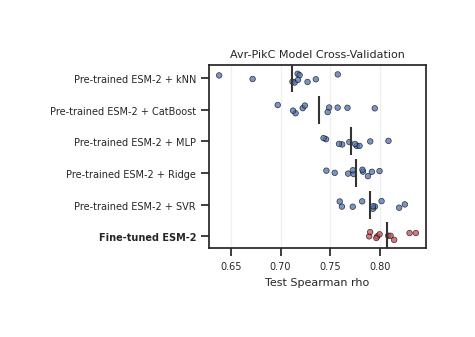

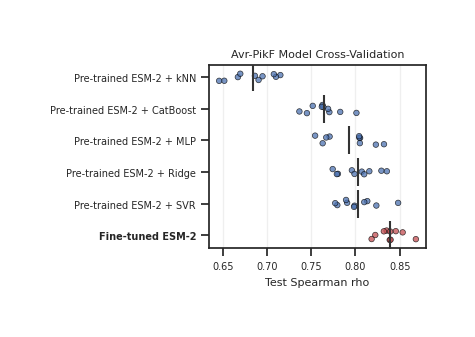

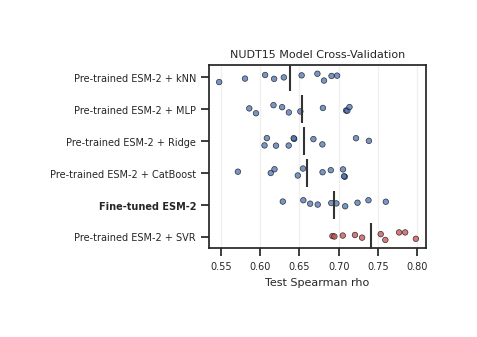

In [ ]:
for cfg in DATASETS:

  # Plot results
  cm = 1 / 2.54
  fig, axes = plt.subplots(1, 1, figsize=(10*cm, 6.5*cm))
  axes = np.atleast_1d(axes)
  for ax, lig in zip(axes, [cfg["name"]]):
    sub = cv[cv["Ligand"] == lig]
    means = sub.groupby("Label")["Spearman"].mean().sort_values()
    order = means.index.tolist()
    best = order[-1]
    sns.stripplot(data=sub, x="Spearman", y="Label", order=order, ax=ax,
                  size=4, alpha=0.75, jitter=0.15, linewidth=0.5, edgecolor="black",
                  hue=sub["Label"].eq(best),
                  palette={True: "#c44e52", False: "#4c72b0"}, legend=False)
    ax.scatter(means.values, range(len(order)), marker="|", s=400, color="0.2", zorder=5)
    ax.set_title(f"{cfg['cv_title']} Model Cross-Validation", fontsize=8)
    ax.set_xlabel("Test Spearman rho", fontsize=8)
    ax.set_ylabel("")
    ax.tick_params(axis='both', labelsize=7)
    for t in ax.get_yticklabels():
      if t.get_text() == "Fine-tuned ESM-2":
        t.set_fontweight("bold")
    ax.grid(axis="x", alpha=0.3)
  plt.tight_layout()
  plt.savefig(f"{OUT_DIR}/figures/{cfg["name"]}_cv_fold_spearman.png", dpi=300, bbox_inches="tight", pad_inches=0.02)
  plt.savefig(f"{OUT_DIR}/figures/{cfg["name"]}_cv_fold_spearman.svg", bbox_inches="tight", pad_inches=0.02)
  plt.show()


## Final SVR model on NUDT15 embeddings

In [ ]:
## Refit the saved model on train + val after hyperparameter selection.
def run_svr_dataset(config, model_name="SVR", tag="svr"):
  """Fit one transfer model on frozen pre-trained embeddings, save predictions and weights."""
  ## Print dataset
  name = config["name"]
  print(f"\n=== {name} ({model_name} on pre-trained embeddings) ===")

  ## Load in dataset, then split into train/val/test sets
  ## Same seed as run_dataset, so the test rows match the fine-tuned model's test rows
  df = pd.read_csv(config["path"]).rename(
      columns={config["seq_col"]: "seq", config["score_col"]: "score"})[["seq", "score"]]
  train_df, val_df, test_df = reproducible_split(df, "seq", seed=SEED)
  print(f"train/val/test sizes: {len(train_df)}/{len(val_df)}/{len(test_df)}")

  ## Load in natural sequence variants to score
  nat_df = pd.read_csv(config["nat_var_path"]).rename(columns={"SEQ": "seq"})
  if "score" not in nat_df:
    nat_df["score"] = np.nan

  ## Pre-trained embeddings for the whole library, reused from cache when present
  X, index = embed_library(config, suffix="X")
  F = {k: X[rows_for(d["seq"], index)] for k, d in
       [("train", train_df), ("val", val_df), ("test", test_df), ("nat", nat_df)]}
  y_train = train_df["score"].to_numpy(dtype=float)
  y_val = val_df["score"].to_numpy(dtype=float)
  y_test = test_df["score"].to_numpy(dtype=float)

  ## Tune on the validation split, then refit on training rows only
  est, grid = build_estimator(model_name)
  tune_n = SVR_MAX_TUNE_N if model_name == "SVR" else None
  model, params = tune_on_val(est, grid, F["train"], y_train, F["val"], y_val, max_tune_n=tune_n)
  print(f"selected hyperparameters: {params}")

  ## Save the fitted pipeline for downstream reuse
  model_path = f"{OUT_DIR}/weights/{name}_{tag}_pretrained.joblib"
  joblib.dump({"model": model, "params": params, "checkpoint": CHECKPOINT,
               "embedding_suffix": "X", "seed": SEED}, model_path)
  print(f"saved model to {model_path}")

  ## Predict on test and natural sequences
  test_df["pred_score"] = np.asarray(model.predict(F["test"])).ravel()
  test_df.to_csv(f"{OUT_DIR}/data/{name}_{tag}_test_predictions.csv", index=False)
  nat_df["pred_score"] = np.asarray(model.predict(F["nat"])).ravel()
  nat_df.to_csv(f"{OUT_DIR}/data/{name}_{tag}_natural_variant_predictions.csv", index=False)

  ## Plot prediction results
  test_df = pd.read_csv(f"{OUT_DIR}/data/{name}_{tag}_test_predictions.csv")
  plot_test_predictions(test_df, config["score_label"], config["legend_labels"],
                        config["legend_title"], f"{name}_{tag}")

  ## Return results
  return {"Ligand": name, "Model": f"Pre-trained ESM-2 + {model_name}",
          "n_train": len(train_df), "n_val": len(val_df), "n_test": len(test_df),
          **basic_metrics(y_test, test_df["pred_score"]), "BestParams": str(params)}

In [ ]:
## Fit the final SVR on NUDT15 only
nudt15_cfg = next(cfg for cfg in DATASETS if cfg["name"] == "NUDT15")
svr_results = pd.DataFrame([run_svr_dataset(nudt15_cfg)])
svr_results.to_csv(f"{OUT_DIR}/data/svr_summary.csv", index=False)
print(svr_results.to_string(index=False))

In [ ]:
## Compare the fine-tuned model against the SVR on the shared NUDT15 test split
name = nudt15_cfg["name"]
ft_test = pd.read_csv(f"{OUT_DIR}/data/{name}_test_predictions.csv")
svr_test = pd.read_csv(f"{OUT_DIR}/data/{name}_svr_test_predictions.csv")

cmp_test = pd.merge(ft_test[["seq", "score", "pred_score"]],
                    svr_test[["seq", "pred_score"]],
                    on="seq", how="inner", suffixes=("_ft", "_svr"))
assert len(cmp_test) == len(ft_test) == len(svr_test), "test splits do not line up between models"
cmp_test.to_csv(f"{OUT_DIR}/data/{name}_ft_vs_svr_test_predictions.csv", index=False)

## Metrics for each model on the same rows, plus how far the two models agree
y = cmp_test["score"].to_numpy(dtype=float)
for label, col in [("Fine-tuned ESM-2", "pred_score_ft"), ("Pre-trained ESM-2 + SVR", "pred_score_svr")]:
  m = basic_metrics(y, cmp_test[col])
  print(f"{label:26s} rho={m['Spearman']:.3f}  RMSE={m['RMSE']:.3f}  acc={m['Accuracy']:.3f}")
agreement = spearmanr(cmp_test["pred_score_ft"], cmp_test["pred_score_svr"]).statistic
print(f"{'Between models':26s} rho={agreement:.3f}")

## Plot natural variant MSA, scores, and effect map

In [3]:
def run_muscle(in_path, out_path):
  """Align with MUSCLE, handling both the v3 and v5 interfaces."""
  exe = shutil.which("muscle")
  if exe is None:
    raise RuntimeError("muscle not found; install it first (apt-get install muscle)")

  ## v5 reports its version on a bare call; v3 uses -in/-out
  probe = subprocess.run([exe, "-version"], capture_output=True, text=True)
  banner = (probe.stdout + probe.stderr).lower()
  v5 = "muscle 5" in banner or "-align" in banner

  cmd = ([exe, "-align", in_path, "-output", out_path] if v5
         else [exe, "-in", in_path, "-out", out_path])
  print(" ".join(cmd))
  res = subprocess.run(cmd, capture_output=True, text=True)
  if res.returncode != 0:
    raise RuntimeError(f"muscle failed:\n{res.stderr[-2000:]}")
  return out_path

def variants_only(row_pos, col_pos, seq_char, msa):
  """White out anything matching Pikh-1; let the scheme color the rest."""
  ## Reference row stays uncoloured so the variants read against it
  if row_pos == ref_idx:
    return "#FFFFFF"
  if seq_char.upper() == ref_seq[col_pos].upper():
    return "#FFFFFF"
  return None

/usr/bin/muscle -align /content/drive/MyDrive/Colab Notebooks/Pik1-DEFT/3kRGP/Output/Pikp_HMA_Variants_Unique.fa -output /content/drive/MyDrive/Colab Notebooks/Pik1-DEFT/Data/msa/Pikp1_HMA_Variants_Unique_Aligned.fa
wrote 14 aligned sequences to /content/drive/MyDrive/Colab Notebooks/Pik1-DEFT/Data/msa/Pikp1_HMA_Variants_Unique_Aligned_Formatted.fa
alignment length: 81


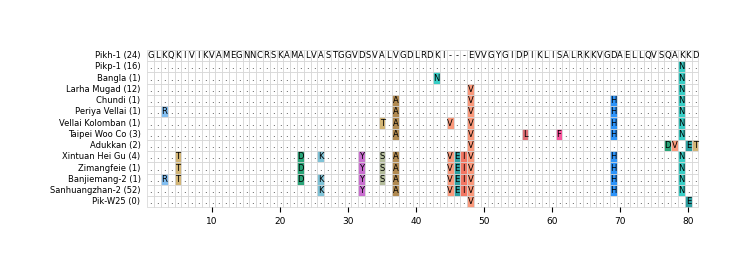

In [6]:
# Align Pik-1 HMA domains with MUSCLE
run_muscle(UNALIGNED_MSA, ALIGNED_MSA)

## Sort on numeric prefix of sequences then remove prefix
aligned = list(SeqIO.parse(ALIGNED_MSA, "fasta"))
aligned.sort(key=lambda r: r.id)
for rec in aligned:
  rec.id = re.sub(r"^..;", "", rec.id)
  rec.name = rec.id
  rec.description = ""
SeqIO.write(aligned, FORMATTED_MSA, "fasta")
print(f"wrote {len(aligned)} aligned sequences to {FORMATTED_MSA}")
print(f"alignment length: {len(aligned[0].seq)}")

# Load formatted MSA
aln = AlignIO.read(FORMATTED_MSA, "fasta")
ref_idx = next(i for i, rec in enumerate(aln) if rec.id == REF_ID)
ref_seq = str(aln[ref_idx].seq)

# Mask residues matching Pikh-1 reference
masked = aln[:, :]
for i, rec in enumerate(masked):
  if i == ref_idx:
    continue
  rec.seq = Seq("".join(c if c.upper() != r.upper() else "." for c, r in zip(str(rec.seq), ref_seq)))
AlignIO.write(masked, MASKED_MSA, "fasta")

# Plot and format MSA
mv = MsaViz(MASKED_MSA, color_scheme="Flower", wrap_length=81, show_grid=True, show_consensus=False, sort=False)
mv.set_custom_color_func(variants_only)
fig = mv.plotfig()
for ax in fig.axes:
  ax.tick_params(axis="x", labelsize=6.5)
  for t in ax.texts:
    t.set_fontsize(6)
    s = t.get_text()
    if "_" in s:
      t.set_text(s.replace("_", " "))
cm = 1 / 2.54
fig.set_size_inches(14*cm, 4*cm)
fig.savefig(f"{OUT_DIR}/figures/Pik1_natural_variants_MSA.png", dpi=300, bbox_inches="tight", pad_inches=0.02)
fig.savefig(f"{OUT_DIR}/figures/Pik1_natural_variants_MSA.svg", bbox_inches="tight", pad_inches=0.02)

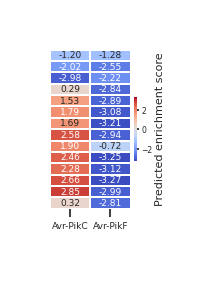

In [ ]:
# Construct heatmap matrix
frames = []
for cfg in DATASETS:
  if cfg["name"] not in HEATMAP_DATASETS:
    continue
  nat = load_dataset_natural(cfg)[["seq", "_label", "_group"]]
  pred = pd.read_csv(f"{OUT_DIR}/data/{cfg['name']}_natural_variant_predictions.csv")
  merged = pd.merge(nat, pred[["seq", "pred_score"]], on="seq", how="left")
  merged["Ligand"] = cfg["cv_title"]
  frames.append(merged)
nat_long = pd.concat(frames, ignore_index=True)
if nat_long["pred_score"].isna().any():
  missing = nat_long["pred_score"].isna().sum()
  print(f"WARNING: {missing} variant/ligand pairs have no prediction")
mat = nat_long.pivot_table(index="_label", columns="Ligand", values="pred_score")
mat = mat[[c["cv_title"] for c in DATASETS if c["name"] in HEATMAP_DATASETS]]

## Row order comes from the MSA, so the heatmap rows line up with the alignment rows
msa_order = [rec.id for rec in aln]        # underscored IDs, pre-renaming
cleaned_msa_order = [re.sub(r'_\(\d+\)$', '', item).replace('_', ' ').replace('Banjiemang2', 'Banjiemang-2').replace(' No 2', '-2') for item in msa_order]
missing = [n for n in cleaned_msa_order if n not in mat.index]
extra = [n for n in mat.index if n not in cleaned_msa_order]
if missing or extra:
  raise ValueError(f"MSA/prediction name mismatch. In MSA only: {missing}. In predictions only: {extra}")
mat = mat.loc[cleaned_msa_order]

# Plot heatmap of Pik-1 scores
lim = np.nanmax(np.abs(mat.to_numpy()))
cm = 1 / 2.54
fig, ax = plt.subplots(figsize=(3*cm, 0.375*len(mat)*cm))
sns.heatmap(mat, cmap="coolwarm", center=0, vmin=-lim, vmax=lim,
            linewidths=0.3, linecolor="white",
            annot=True, fmt=".2f", annot_kws={"size": 6.5},
            cbar_kws={"label": "Predicted enrichment score", "shrink": 0.4,
                      "fraction": 0.08, "pad": 0.04}, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_yticks([])
ax.tick_params(axis="x", labelsize=6.5, rotation=0)
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=5.5, length=1.5, pad=1.25)
cbar.set_label("Predicted enrichment score", size=8, labelpad=2)
plt.savefig(f"{OUT_DIR}/figures/natural_variant_prediction_heatmap.png", dpi=300, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{OUT_DIR}/figures/natural_variant_prediction_heatmap.svg", bbox_inches="tight", pad_inches=0.02)
plt.show()

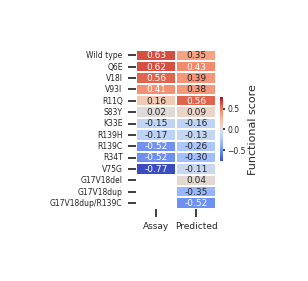

In [ ]:
#Pull in natural variants scoring from SVR model
nudt15_var_svr = pd.read_csv(f"{OUT_DIR}/data/NUDT15_svr_natural_variant_predictions.csv").rename(
      columns={"score": "Assay", "pred_score": "Predicted"}).sort_values(by="Assay",ascending=False)
nudt15_var_svr["variant"] = nudt15_var_svr["variant"].str.replace("WT", "Wild type", regex=False)
nudt15_var_svr.set_index("variant", inplace=True)
nudt15_var_svr = nudt15_var_svr[nudt15_var_svr["effect"].isin(["Benign","Cytotoxic"])][["Assay", "Predicted"]]

#Plot heatmap of scoring for assay vs SVR model
lim = np.nanmax(np.abs(nudt15_var_svr.to_numpy()))
cm = 1 / 2.54
fig, ax = plt.subplots(figsize=(3*cm, 0.375*len(nudt15_var_svr)*cm))
sns.heatmap(nudt15_var_svr, cmap="coolwarm", center=0, vmin=-lim, vmax=lim,
            linewidths=0.3, linecolor="white",
            annot=True, fmt=".2f", annot_kws={"size": 6.5},
            cbar_kws={"label": "Predicted enrichment score", "shrink": 0.4,
                      "fraction": 0.08, "pad": 0.04}, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", labelsize=6.5, rotation=0)
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=5.5, length=1.5, pad=1.25)
cbar.set_label("Functional score", size=8, labelpad=2)
plt.savefig(f"{OUT_DIR}/figures/nudt15_variant_prediction_heatmap.png", dpi=300, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{OUT_DIR}/figures/nudt15_variant_prediction_heatmap.svg", bbox_inches="tight", pad_inches=0.02)
plt.show()

variants plotted: 29


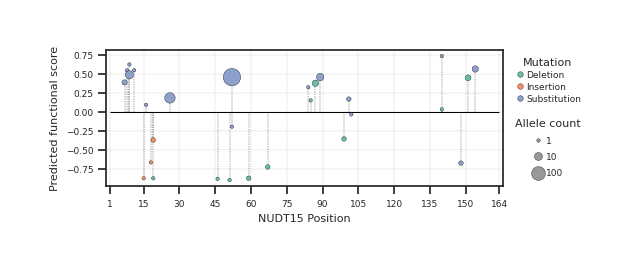

In [ ]:
## Load in and format data for plotting
nudt15_var_svr = pd.read_csv(f"{OUT_DIR}/data/NUDT15_svr_natural_variant_predictions.csv")
unchar = nudt15_var_svr[nudt15_var_svr["effect"] == "Uncharacterized"].copy()
unchar[["wt_res", "pos", "mut_res"]] = unchar["variant"].str.extract(r"([A-Za-z]+)(\d+)(.*)")
unchar["pos"] = unchar["pos"].astype(int)
unchar["mut_type"] = unchar["mut_res"].str.extract(r"(ins|del|dup)").fillna("sub")
mapping = {
    'ins': 'Insertion',
    'del': 'Deletion',
    'dup': 'Insertion',
    'sub': 'Substitution',
}
unchar["mut_type"] = unchar["mut_type"].map(mapping)

unchar = unchar.dropna(subset=["pos", "pred_score", "Allele Count"])
print(f"variants plotted: {len(unchar)}")

## One size mapping shared by the scatter and the legend.
## s in scatter is marker AREA in pt^2; markersize in Line2D is DIAMETER in pt.
D_MIN, D_MAX = 2.5, 12.5          # marker diameter range in points
LOG_SIZE = True                  # allele counts are usually heavily right-skewed

counts = unchar["Allele Count"].to_numpy(dtype=float)
_t = (lambda c: np.log10(np.asarray(c, dtype=float) + 1)) if LOG_SIZE else (lambda c: np.asarray(c, dtype=float))
v_lo, v_hi = _t(counts).min(), _t(counts).max()

def size_for(count):
  """Allele count to marker area in pt^2."""
  f = (_t(count) - v_lo) / max(v_hi - v_lo, 1e-9)
  return (D_MIN + f * (D_MAX - D_MIN)) ** 2

unchar["_size"] = size_for(counts)

## Set up plot
cm = 1 / 2.54
sns.set_theme(style="ticks", font_scale=1.0)
fig, ax = plt.subplots(figsize=(13*cm, 4.5*cm))

## Dashed stems down to zero, drawn under the markers
ax.vlines(unchar["pos"], 0, unchar["pred_score"],
          colors="black", linewidths=0.25, linestyles=(0, (4, 3)), zorder=2)

## Baseline spanning the full protein
ax.hlines(0, 1, 164, colors="black", linewidth=0.75, zorder=3)

## Set2, matching scale_fill_brewer
types = sorted(unchar["mut_type"].unique())
palette = dict(zip(types, sns.color_palette("Set2", len(types))))
for t in types:
  sub = unchar[unchar["mut_type"] == t]
  ax.scatter(sub["pos"], sub["pred_score"], s=sub["_size"], c=[palette[t]],
             marker="o", edgecolors="black", linewidths=0.25, zorder=4)

ax.set_xlim(1 - 164*0.01, 164 + 164*0.01)
ax.set_xticks([1, 15, 30, 45, 60, 75, 90, 105, 120, 135, 150, 164])
ax.set_xlabel("NUDT15 Position", fontsize=8)
ax.set_ylabel("Predicted functional score", fontsize=8)
ax.set_yticks([-0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75])
ax.tick_params(labelsize=6.5)
ax.grid(which="minor", visible=False)
ax.grid(which="major", linewidth=0.25)

## Mutation type legend, fixed marker size so it encodes colour only
type_handles = [Line2D([], [], marker="o", linestyle="none", color=palette[t],
                       markeredgecolor="black", markeredgewidth=0.25,
                       markersize=4, label=t)
                for t in types]
type_leg = ax.legend(handles=type_handles, title="Mutation",
                     fontsize=6.5, title_fontsize=8, loc="upper left",
                     bbox_to_anchor=(1.01, 1.0), frameon=False,
                     labelspacing=0.3, handletextpad=0.2)
ax.add_artist(type_leg)

## Allele count legend, sizes pulled from the same mapping as the scatter
breaks = [b for b in [1, 10, 100] if counts.min() <= b <= counts.max()]
size_handles = [Line2D([], [], marker="o", linestyle="none", color="0.6",
                       markeredgecolor="black", markeredgewidth=0.25,
                       markersize=np.sqrt(size_for(b)), label=str(b))
                for b in breaks]
ax.legend(handles=size_handles, title="Allele count", fontsize=6.5,
          title_fontsize=8, loc="lower left", bbox_to_anchor=(1.01, 0.0),
          frameon=False, labelspacing=0.8, handletextpad=0.4)

plt.savefig(f"{OUT_DIR}/figures/NUDT15_predicted_effects.png",
            dpi=300, bbox_inches="tight", pad_inches=0.02)
plt.savefig(f"{OUT_DIR}/figures/NUDT15_predicted_effects.svg",
            bbox_inches="tight", pad_inches=0.02)
plt.show()